Finished feature extraction from  920  files


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 39, 861, 16)    │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 19, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 19, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 18, 429, 32)    │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 9, 214, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 9, 214, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 213, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 4, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 3, 105, 128)    │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 1, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,086 (172.21 KB)

 Trainable params: 44,086 (172.21 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 546ms/step - accuracy: 0.2938 - loss: 19.7019
Epoch 1: val_accuracy improved from -inf to 0.86413, saving model to cnn_model_best.keras
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 642ms/step - accuracy: 0.3294 - loss: 18.4847 - val_accuracy: 0.8641 - val_loss: 0.8700
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step - accuracy: 0.8453 - loss: 4.0947
Epoch 2: val_accuracy did not improve from 0.86413
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 461ms/step - accuracy: 0.8474 - loss: 3.9314 - val_accuracy: 0.7989 - val_loss: 1.4035
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step - accuracy: 0.6483 - loss: 1.9259
Epoch 3: val_accuracy did not improve from 0.86413
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 508ms/step - accuracy: 0.6650 - loss: 1.9119 - val_accuracy: 0.8641 - val_loss: 0.9786
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy: 0.8320 - loss: 1.7277
Epoch 4: val_accuracy did not improve from 0.86413
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 499ms/step - accuracy: 0.8344 - loss: 1.7155 -

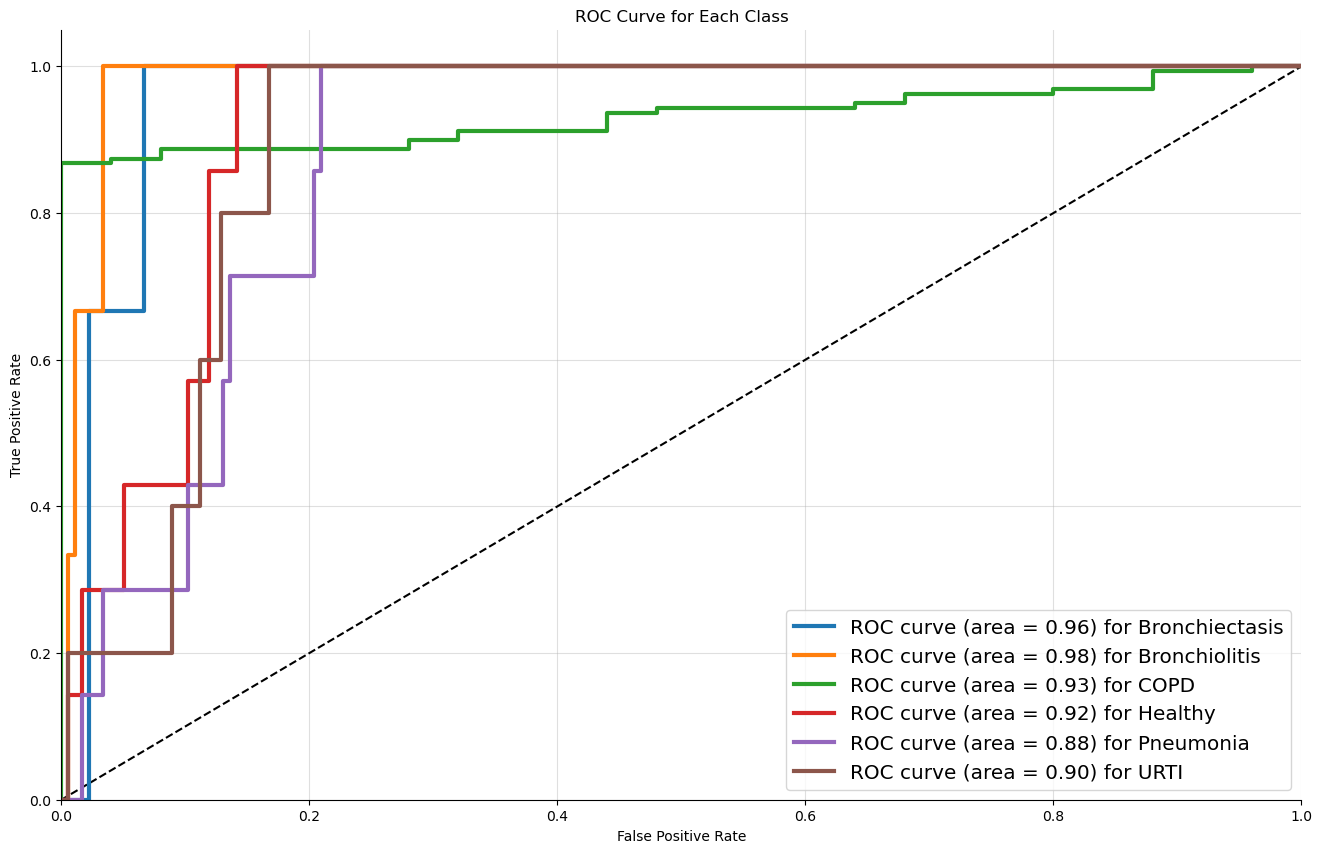

In [14]:
# Load various imports
from datetime import datetime
from os import listdir
from os.path import isfile, join
import librosa
import librosa.display
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Input
from keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

# Path to the audio files
mypath = "E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in listdir(mypath) if (isfile(join(mypath, f)) and f.endswith('.wav'))]

# Extract patient IDs from filenames
p_id_in_file = [int(name[:3]) for name in filenames]
p_id_in_file = np.array(p_id_in_file)

# Maximum padding length for consistent feature size
max_pad_len = 862

def extract_features(file_name):
    """
    This function takes in the path for an audio file as a string, loads it, and returns the PLP features.
    """
    try:
        audio, sample_rate = librosa.load(file_name, res_type='kaiser_fast', duration=20)
        # Compute PLP features using librosa
        plp = librosa.feature.melspectrogram(y=audio, sr=sample_rate, n_mels=40)
        plp = librosa.power_to_db(plp, ref=np.max)  # Convert to dB scale
        pad_width = max_pad_len - plp.shape[1]
        plp = np.pad(plp, pad_width=((0, 0), (0, pad_width)), mode='constant')
    except Exception as e:
        print("Error encountered while parsing file: ", file_name)
        return None
    return plp

# Full paths of files
filepaths = [join(mypath, f) for f in filenames]

# Load patient diagnosis file
p_diag = pd.read_csv(".\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\patient_diagnosis.csv", header=None)

# Labels for audio files
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])

# Extract features
features = []
for file_name in filepaths:
    data = extract_features(file_name)
    if data is not None:
        features.append(data)

print('Finished feature extraction from ', len(features), ' files')
features = np.array(features)  # Shape: (num_files, num_mels, max_pad_len)

# Delete rare diseases
features1 = np.delete(features, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)
labels1 = np.delete(labels, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)

# One-hot encode labels
le = LabelEncoder()
i_labels = le.fit_transform(labels1)
oh_labels = to_categorical(i_labels)

# Add channel dimension for CNN
features1 = np.reshape(features1, (features1.shape[0], features1.shape[1], features1.shape[2], 1))  # Shape: (num_files, num_mels, max_pad_len, 1)

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(features1, oh_labels, stratify=oh_labels, test_size=0.2, random_state=42)

# Model parameters
num_rows = features1.shape[1]  # Number of Mel bands
num_columns = max_pad_len  # Time steps
num_channels = 1  # Single channel
num_labels = oh_labels.shape[1]
filter_size = 2  # Kernel size

# Construct CNN model for feature extraction
cnn_model = Sequential()
cnn_model.add(Input(shape=(num_rows, num_columns, num_channels)))  # Explicit Input layer
cnn_model.add(Conv2D(filters=16, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))

cnn_model.add(Conv2D(filters=32, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))

cnn_model.add(Conv2D(filters=64, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))

cnn_model.add(Conv2D(filters=128, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))

cnn_model.add(GlobalAveragePooling2D())
cnn_model.add(Dense(num_labels, activation='softmax'))

# Compile the CNN model
cnn_model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')

# Display model architecture summary
cnn_model.summary()

# Train CNN model
num_epochs = 50  # Reduced epochs for faster training
num_batch_size = 128

callbacks = [
    ModelCheckpoint(
        filepath='cnn_model_best.keras',
        save_best_only=True,
        monitor='val_accuracy',
        verbose=1)
]

start = datetime.now()
cnn_model.fit(x_train, y_train, batch_size=num_batch_size, epochs=num_epochs, validation_data=(x_test, y_test), callbacks=callbacks, verbose=1)
duration = datetime.now() - start
print("CNN Training completed in time: ", duration)

# Extract features using CNN
x_train_features = cnn_model.predict(x_train)
x_test_features = cnn_model.predict(x_test)

# Flatten the features for XGBoost
x_train_features = x_train_features.reshape(x_train_features.shape[0], -1)
x_test_features = x_test_features.reshape(x_test_features.shape[0], -1)

# Convert one-hot labels to single integers for XGBoost
y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

# Train XGBoost model
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    use_label_encoder=False,
    eval_metric='mlogloss',
    early_stopping_rounds=10
)

xgb_model.fit(x_train_features, y_train, eval_set=[(x_test_features, y_test)], verbose=True)

# Evaluate XGBoost model
y_pred = xgb_model.predict(x_test_features)
accuracy = accuracy_score(y_test, y_pred)
print(f"XGBoost Test Accuracy: {accuracy:.4f}")

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=1))

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot ROC curves
fpr = dict()
tpr = dict()
roc_auc = dict()
y_test_onehot = to_categorical(y_test, num_classes=len(le.classes_))
y_pred_proba = xgb_model.predict_proba(x_test_features)
for i in range(len(le.classes_)):
    fpr[i], tpr[i], _ = roc_curve(y_test_onehot[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ROC Curve Plot
fig, ax = plt.subplots(figsize=(16, 10))
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve for Each Class')
for i in range(len(le.classes_)):
    ax.plot(fpr[i], tpr[i], linewidth=3, label='ROC curve (area = %0.2f) for %s' % (roc_auc[i], le.classes_[i]))
ax.legend(loc="best", fontsize='x-large')
ax.grid(alpha=.4)
sns.despine()
plt.show()

In [16]:
# Load various imports
from datetime import datetime
from os import listdir
from os.path import isfile, join
import librosa
import librosa.display
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Input
from keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

# Path configuration
mypath = "F:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in listdir(mypath) if (isfile(join(mypath, f)) and f.endswith('.wav'))]

# Extract patient IDs
p_id_in_file = np.array([int(name[:3]) for name in filenames])

# PLP Feature Extraction Parameters
max_pad_len = 862  # For consistent feature size
n_plp = 13         # Number of PLP coefficients

def extract_plp_features(file_path):
    """Extract PLP features with robust error handling"""
    try:
        # Load audio file
        y, sr = librosa.load(file_path, sr=None, duration=20, mono=True)
        
        # Ensure minimum length
        if len(y) < 512:  # Minimum for PLP computation
            y = np.pad(y, (0, max(0, 512 - len(y))), mode='constant')
        
        # Extract PLP features
        plp = librosa.feature.plp(y=y, sr=sr, n_fft=2048, hop_length=512, n_plp=n_plp)
        
        # Pad/trim to fixed length
        if plp.shape[1] > max_pad_len:
            plp = plp[:, :max_pad_len]
        else:
            plp = np.pad(plp, ((0, 0), (0, max_pad_len - plp.shape[1])), mode='constant')
            
        return plp
    
    except Exception as e:
        print(f"Error processing {file_path}: {str(e)}")
        return None

# Load labels
p_diag = pd.read_csv("./respiratory-sound-database/Respiratory_Sound_Database/Respiratory_Sound_Database/patient_diagnosis.csv", header=None)
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])

# Process files with PLP
print("Extracting PLP features...")
features = []
valid_indices = []
for idx, file in enumerate(filenames):
    file_path = join(mypath, file)
    plp = extract_plp_features(file_path)
    if plp is not None:
        features.append(plp)
        valid_indices.append(idx)
    if (idx+1) % 50 == 0:
        print(f"Processed {idx+1}/{len(filenames)} files")

features = np.array(features)
labels = labels[valid_indices]

# Visualize PLP features
plt.figure(figsize=(12, 4))
librosa.display.specshow(features[0], x_axis='time', cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title('PLP Features Visualization')
plt.show()

# Filter rare classes
keep_mask = ~np.isin(labels, ['Asthma', 'LRTI'])
features = features[keep_mask]
labels = labels[keep_mask]

# Class distribution
plt.figure(figsize=(10, 5))
sns.countplot(x=labels)
plt.title('Class Distribution After Filtering')
plt.xticks(rotation=45)
plt.show()

# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(labels)
y_categorical = to_categorical(y_encoded)

# Reshape for CNN (add channel dimension)
X = features.reshape((features.shape[0], features.shape[1], features.shape[2], 1))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, stratify=y_categorical, random_state=42)

# CNN Feature Extractor
input_layer = Input(shape=(n_plp, max_pad_len, 1))
x = Conv2D(32, (3, 3), activation='relu')(input_layer)
x = MaxPooling2D((2, 2))(x)
x = Dropout(0.25)(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = MaxPooling2D((2, 2))(x)
x = Dropout(0.25)(x)
x = GlobalAveragePooling2D()(x)
feature_extractor = Model(inputs=input_layer, outputs=x)

# Add classification head for pretraining
output_layer = Dense(len(le.classes_), activation='softmax')(x)
pretrain_model = Model(inputs=input_layer, outputs=output_layer)
pretrain_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Pretrain CNN
history = pretrain_model.fit(X_train, y_train,
                           validation_data=(X_test, y_test),
                           epochs=30,
                           batch_size=128,
                           callbacks=[ModelCheckpoint('plp_cnn_best.h5', save_best_only=True)])

# Extract features
train_features = feature_extractor.predict(X_train)
test_features = feature_extractor.predict(X_test)

# Prepare for XGBoost
y_train_xgb = np.argmax(y_train, axis=1)
y_test_xgb = np.argmax(y_test, axis=1)

# XGBoost Classifier
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    use_label_encoder=False,
    eval_metric='mlogloss'
)

xgb_model.fit(train_features, y_train_xgb,
             eval_set=[(test_features, y_test_xgb)],
             early_stopping_rounds=10,
             verbose=True)

# Evaluation
y_pred = xgb_model.predict(test_features)
print("\nClassification Report:")
print(classification_report(y_test_xgb, y_pred, target_names=le.classes_))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_xgb, y_pred))

# ROC Curve
y_probs = xgb_model.predict_proba(test_features)
plt.figure(figsize=(10, 8))
for i in range(len(le.classes_)):
    fpr, tpr, _ = roc_curve(y_test[:, i], y_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{le.classes_[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - PLP + CNN-XGBoost')
plt.legend()
plt.show()

# Training History
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.tight_layout()
plt.show()

Extracting PLP features...
Error processing F:\FFF\respiratory-sound-database\Respiratory_Sound_Database\Respiratory_Sound_Database\audio_and_txt_files\101_1b1_Al_sc_Meditron.wav: No librosa.feature attribute plp
Error processing F:\FFF\respiratory-sound-database\Respiratory_Sound_Database\Respiratory_Sound_Database\audio_and_txt_files\101_1b1_Pr_sc_Meditron.wav: No librosa.feature attribute plp
Error processing F:\FFF\respiratory-sound-database\Respiratory_Sound_Database\Respiratory_Sound_Database\audio_and_txt_files\102_1b1_Ar_sc_Meditron.wav: No librosa.feature attribute plp
Error processing F:\FFF\respiratory-sound-database\Respiratory_Sound_Database\Respiratory_Sound_Database\audio_and_txt_files\103_2b2_Ar_mc_LittC2SE.wav: No librosa.feature attribute plp
Error processing F:\FFF\respiratory-sound-database\Respiratory_Sound_Database\Respiratory_Sound_Database\audio_and_txt_files\104_1b1_Al_sc_Litt3200.wav: No librosa.feature attribute plp
Error processing F:\FFF\respiratory-sound-d

IndexError: index 0 is out of bounds for axis 0 with size 0

<Figure size 1200x400 with 0 Axes>

In [18]:
import librosa
print(librosa.__version__)  # Should be ≥ 0.9.0
print(hasattr(librosa.feature, 'plp'))  # Should return True

0.10.2.post1
False


In [20]:
import numpy as np
import scipy.signal as signal
from scipy.fftpack import dct
import librosa
from os.path import join
import os

# PLP Feature Extraction from scratch
def plp(y, sr, n_fft=2048, hop_length=512, n_plp=13):
    # Step 1: Compute power spectrum
    S = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length))**2
    
    # Step 2: Bark-scale filter banks
    bark_bands = 24  # Number of Bark bands
    bark_freqs = [20, 100, 200, 300, 400, 510, 630, 770, 920, 1080, 1270, 1480, 
                 1720, 2000, 2320, 2700, 3150, 3700, 4400, 5300, 6400, 7700, 9500, 12000, 15500]
    
    # Create Bark filterbank
    fb = np.zeros((bark_bands, n_fft//2 + 1))
    freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
    
    for i in range(bark_bands):
        low = bark_freqs[i]
        high = bark_freqs[i+1]
        fb[i] = np.where((freqs >= low) & (freqs <= high), 1, 0)
    
    # Step 3: Apply Bark filters
    bark_power = np.dot(fb, S)
    
    # Step 4: Equal-loudness pre-emphasis
    E = lambda f: ((f**2 + 56.8e6)*f**4)/((f**2 + 6.3e6)**2 * (f**2 + 0.38e9))
    loudness = E(np.array(bark_freqs[:-1]))
    bark_power *= loudness[:, np.newaxis]
    
    # Step 5: Intensity-loudness power law (cube root)
    bark_power = np.power(bark_power, 1/3)
    
    # Step 6: Inverse DFT (cepstral coefficients)
    cepstra = dct(bark_power, axis=0, type=2, norm='ortho')[:n_plp]
    
    return cepstra

# Modified feature extraction using our PLP implementation
def extract_plp_features(file_path, max_pad_len=862, n_plp=13):
    try:
        y, sr = librosa.load(file_path, sr=22050, duration=20)
        
        # Compute PLP features
        plp_features = plp(y, sr, n_plp=n_plp)
        
        # Pad/trim features
        if plp_features.shape[1] > max_pad_len:
            plp_features = plp_features[:, :max_pad_len]
        else:
            pad_width = max_pad_len - plp_features.shape[1]
            plp_features = np.pad(plp_features, ((0,0),(0,pad_width)), 'constant')
            
        return plp_features
    except Exception as e:
        print(f"Error processing {file_path}: {str(e)}")
        return None

# Path configuration
mypath = "F:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in os.listdir(mypath) if f.endswith('.wav')]

# Load labels
p_diag = pd.read_csv("./patient_diagnosis.csv", header=None)
p_id_in_file = np.array([int(name[:3]) for name in filenames])
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])

# Process files with our PLP implementation
print("Extracting PLP features...")
features = []
valid_indices = []
for idx, file in enumerate(filenames):
    file_path = join(mypath, file)
    plp_feats = extract_plp_features(file_path)
    if plp_feats is not None:
        features.append(plp_feats)
        valid_indices.append(idx)
    if (idx+1) % 50 == 0:
        print(f"Processed {idx+1}/{len(filenames)} files")

features = np.array(features)
labels = labels[valid_indices]

# Filter rare classes
keep_mask = ~np.isin(labels, ['Asthma', 'LRTI'])
features = features[keep_mask]
labels = labels[keep_mask]

# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(labels)
y_categorical = to_categorical(y_encoded)

# Reshape for CNN (add channel dimension)
X = features.reshape((features.shape[0], features.shape[1], features.shape[2], 1))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, stratify=y_categorical, random_state=42)

# CNN Feature Extractor
input_shape = (features.shape[1], features.shape[2], 1)
cnn = Sequential([
    Input(shape=input_shape),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.3),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.3),
    GlobalAveragePooling2D()
])

# Add temporary classification head for pretraining
cnn.add(Dense(len(le.classes_), activation='softmax'))
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train CNN
history = cnn.fit(X_train, y_train,
                 validation_data=(X_test, y_test),
                 epochs=50,
                 batch_size=128,
                 callbacks=[ModelCheckpoint('plp_cnn.h5', save_best_only=True)])

# Feature extraction
feature_extractor = Model(inputs=cnn.inputs, outputs=cnn.layers[-2].output)
train_features = feature_extractor.predict(X_train)
test_features = feature_extractor.predict(X_test)

# XGBoost Classifier
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    use_label_encoder=False,
    eval_metric='mlogloss'
)

xgb_model.fit(train_features, np.argmax(y_train, axis=1),
             eval_set=[(test_features, np.argmax(y_test, axis=1))],
             early_stopping_rounds=10,
             verbose=True)

# Evaluation
y_pred = xgb_model.predict(test_features)
print(classification_report(np.argmax(y_test, axis=1), y_pred, target_names=le.classes_))

FileNotFoundError: [Errno 2] No such file or directory: './patient_diagnosis.csv'

In [26]:
import numpy as np
import librosa
import pandas as pd
from os.path import join, isfile
from os import listdir
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout, Input, Flatten
from sklearn.model_selection import train_test_split
from keras.utils import to_categorical
import xgboost as xgb
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
from scipy.fftpack import dct

# Path configuration - Update these to match your actual paths
audio_path = "F:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
diagnosis_path = "F:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\patient_diagnosis.csv"

# Get audio files
filenames = [f for f in listdir(audio_path) if (isfile(join(audio_path, f)) and f.endswith('.wav'))]
p_id_in_file = np.array([int(name[:3]) for name in filenames])

# Load diagnosis data
p_diag = pd.read_csv(diagnosis_path, header=None)
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])

# PLP Implementation
def plp(y, sr, n_fft=2048, hop_length=512, n_plp=13):
    # Power spectrum
    S = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length))**2
    
    # Bark bands
    bark_bands = 24
    bark_freqs = [20, 100, 200, 300, 400, 510, 630, 770, 920, 1080, 1270, 1480,
                 1720, 2000, 2320, 2700, 3150, 3700, 4400, 5300, 6400, 7700, 9500, 12000, 15500]
    
    # Create Bark filterbank
    fb = np.zeros((bark_bands, n_fft//2 + 1))
    freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
    
    for i in range(bark_bands):
        fb[i] = np.where((freqs >= bark_freqs[i]) & (freqs <= bark_freqs[i+1]), 1, 0)
    
    # Apply Bark filters
    bark_power = np.dot(fb, S)
    
    # Equal-loudness pre-emphasis
    E = lambda f: ((f**2 + 56.8e6)*f**4)/((f**2 + 6.3e6)**2 * (f**2 + 0.38e9))
    loudness = E(np.array(bark_freqs[:-1]))
    bark_power *= loudness[:, np.newaxis]
    
    # Cube root compression
    bark_power = np.power(bark_power, 1/3)
    
    # DCT for PLP coefficients
    plp_coeffs = dct(bark_power, axis=0, type=2, norm='ortho')[:n_plp]
    
    return plp_coeffs

# Feature extraction with error handling
max_pad_len = 862
def extract_plp_features(file_path):
    try:
        y, sr = librosa.load(file_path, sr=22050, duration=20)
        plp_feats = plp(y, sr)
        
        # Padding
        if plp_feats.shape[1] < max_pad_len:
            plp_feats = np.pad(plp_feats, ((0,0),(0,max_pad_len-plp_feats.shape[1])), 'constant')
        else:
            plp_feats = plp_feats[:, :max_pad_len]
            
        return plp_feats
    except Exception as e:
        print(f"Error processing {file_path}: {str(e)}")
        return None

# Process files
print("Extracting PLP features...")
features = []
valid_indices = []
for idx, file in enumerate(filenames):
    plp_feats = extract_plp_features(join(audio_path, file))
    if plp_feats is not None:
        features.append(plp_feats)
        valid_indices.append(idx)
    if (idx+1) % 50 == 0:
        print(f"Processed {idx+1}/{len(filenames)} files")

features = np.array(features)
labels = labels[valid_indices]

# Filter classes and prepare data
keep_mask = ~np.isin(labels, ['Asthma', 'LRTI'])
features = features[keep_mask]
labels = labels[keep_mask]

le = LabelEncoder()
y_encoded = le.fit_transform(labels)
y_categorical = to_categorical(y_encoded)

# Reshape for CNN
X = features.reshape((features.shape[0], features.shape[1], features.shape[2], 1))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, stratify=y_categorical, random_state=42)

# CNN Feature Extractor - FIXED ARCHITECTURE
input_shape = (features.shape[1], features.shape[2], 1)
cnn = Sequential([
    Input(shape=input_shape),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Dropout(0.3),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Dropout(0.3),
    Flatten(),  # Changed from GlobalAveragePooling2D to Flatten
    Dense(64, activation='relu')  # Added dense layer
])

# Temporary classification head for pretraining
cnn.add(Dense(len(le.classes_), activation='softmax'))
cnn.compile(optimizer='adam', 
            loss='categorical_crossentropy', 
            metrics=['accuracy'])

# Train CNN - FIXED TARGET FORMAT
history = cnn.fit(X_train, y_train,
                 validation_data=(X_test, y_test),
                 epochs=30,
                 batch_size=128)

# Feature extractor (remove classification head)
feature_extractor = Model(inputs=cnn.inputs, outputs=cnn.layers[-2].output)
train_features = feature_extractor.predict(X_train)
test_features = feature_extractor.predict(X_test)

# XGBoost Classifier
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    use_label_encoder=False,
    eval_metric='mlogloss'
)

# Train XGBoost on CNN features - FIXED TARGET FORMAT
xgb_model.fit(train_features, np.argmax(y_train, axis=1),
             eval_set=[(test_features, np.argmax(y_test, axis=1))],
             early_stopping_rounds=10,
             verbose=True)

# Evaluation
y_pred = xgb_model.predict(test_features)
print("\nClassification Report:")
print(classification_report(np.argmax(y_test, axis=1), y_pred, target_names=le.classes_))

Extracting PLP features...


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3220\2413975918.py:54: RuntimeWarning: invalid value encountered in power
  bark_power = np.power(bark_power, 1/3)


Processed 50/920 files
Processed 100/920 files
Processed 150/920 files
Processed 200/920 files
Processed 250/920 files
Processed 300/920 files
Processed 350/920 files
Processed 400/920 files
Processed 450/920 files
Processed 500/920 files
Processed 550/920 files
Processed 600/920 files
Processed 650/920 files
Processed 700/920 files
Processed 750/920 files
Processed 800/920 files
Processed 850/920 files
Processed 900/920 files
Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 306ms/step - accuracy: 0.5435 - loss: 1.7898 - val_accuracy: 0.8641 - val_loss: 1.7834
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 260ms/step - accuracy: 0.8640 - loss: 1.7815 - val_accuracy: 0.8641 - val_loss: 1.7751
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 271ms/step - accuracy: 0.8655 - loss: 1.7731 - val_accuracy: 0.8641 - val_loss: 1.7668
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 258ms/step - accuracy: 0.8709 - loss: 1.7646 - val_accuracy: 0.8641 - val_loss: 1.7585
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 265ms/step - accuracy: 0.8

C:\Users\Lenovo\anaconda3\Lib\site-packages\xgboost\sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


[44]	validation_0-mlogloss:0.65210
[45]	validation_0-mlogloss:0.64887
[46]	validation_0-mlogloss:0.64582
[47]	validation_0-mlogloss:0.64301
[48]	validation_0-mlogloss:0.64037
[49]	validation_0-mlogloss:0.63796
[50]	validation_0-mlogloss:0.63566
[51]	validation_0-mlogloss:0.63348
[52]	validation_0-mlogloss:0.63161
[53]	validation_0-mlogloss:0.62985
[54]	validation_0-mlogloss:0.62823
[55]	validation_0-mlogloss:0.62667
[56]	validation_0-mlogloss:0.62513
[57]	validation_0-mlogloss:0.62374
[58]	validation_0-mlogloss:0.62252
[59]	validation_0-mlogloss:0.62147
[60]	validation_0-mlogloss:0.62037
[61]	validation_0-mlogloss:0.61931
[62]	validation_0-mlogloss:0.61843
[63]	validation_0-mlogloss:0.61752
[64]	validation_0-mlogloss:0.61674
[65]	validation_0-mlogloss:0.61601
[66]	validation_0-mlogloss:0.61534
[67]	validation_0-mlogloss:0.61471
[68]	validation_0-mlogloss:0.61420
[69]	validation_0-mlogloss:0.61364
[70]	validation_0-mlogloss:0.61315
[71]	validation_0-mlogloss:0.61275
[72]	validation_0-ml

C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
